In [1]:
# Step 1: Dataset Ingestion & Integrity Check
import pandas as pd

# Load the dataset
df = pd.read_csv('European_Bank.csv')

print("============================================================")
print("             DATASET INGESTION & INTEGRITY CHECK")
print("============================================================\n")

print(f"Total Observations (Rows): {df.shape[0]}")
print(f"Total Features (Columns): {df.shape[1]}")

print("\nMissing Values per Feature:")
missing_vals = df.isnull().sum()
print(missing_vals[missing_vals > 0] if missing_vals.sum() > 0 else "None! (Dataset is completely populated)")

print("\nDuplicate Customer IDs:")
print(df['CustomerId'].duplicated().sum())

print("\nTarget Variable Distribution ('Exited'):")
churn_counts = df['Exited'].value_counts()
churn_percentages = df['Exited'].value_counts(normalize=True) * 100

for status in [0, 1]:
    label = "Retained (0)" if status == 0 else "Churned (1)"
    print(f"{label}: {churn_counts[status]:,} customers ({churn_percentages[status]:.2f}%)")

print("\n============================================================")

             DATASET INGESTION & INTEGRITY CHECK

Total Observations (Rows): 10000
Total Features (Columns): 14

Missing Values per Feature:
None! (Dataset is completely populated)

Duplicate Customer IDs:
0

Target Variable Distribution ('Exited'):
Retained (0): 7,963 customers (79.63%)
Churned (1): 2,037 customers (20.37%)



In [2]:
# ============================================================
# STEP 2: DATA PREPROCESSING & FEATURE ENGINEERING
# ============================================================
import numpy as np

# 1. Drop non-informative features
# Using errors='ignore' ensures it won't crash if 'RowNumber' or 'Year' varies by dataset version
df_clean = df.drop(columns=['RowNumber', 'Year', 'CustomerId', 'Surname'], errors='ignore')

# 2. Categorical Encoding
# drop_first=True prevents multicollinearity (the dummy variable trap)
df_clean = pd.get_dummies(df_clean, columns=['Geography', 'Gender'], drop_first=True)

# 3. Feature Engineering (Derived Features)
# Balance-to-Salary ratio (adding 1e-6 to prevent division by zero in edge cases)
df_clean['Balance_to_Salary'] = df_clean['Balance'] / (df_clean['EstimatedSalary'] + 1e-6)

# Product density indicator (NumOfProducts per year of tenure)
# np.where handles customers with 0 tenure to avoid division by zero errors
df_clean['Product_Density'] = np.where(
    df_clean['Tenure'] == 0, 
    df_clean['NumOfProducts'], 
    df_clean['NumOfProducts'] / df_clean['Tenure']
)

# Engagement-product interaction
df_clean['Engagement_Product'] = df_clean['IsActiveMember'] * df_clean['NumOfProducts']

# Age-tenure interaction
df_clean['Age_Tenure'] = df_clean['Age'] * df_clean['Tenure']

# 4. Validation Printout
print("============================================================")
print("             PREPROCESSING & ENGINEERING COMPLETE")
print("============================================================")
print(f"New Dataset Shape: {df_clean.shape[0]} rows, {df_clean.shape[1]} columns\n")
print("Current Feature Set:")
for col in df_clean.columns:
    print(f" - {col}")
print("============================================================")

# Preview the engineered features for the first 3 rows
df_clean[['Balance_to_Salary', 'Product_Density', 'Engagement_Product', 'Age_Tenure']].head(3)

             PREPROCESSING & ENGINEERING COMPLETE
New Dataset Shape: 10000 rows, 16 columns

Current Feature Set:
 - CreditScore
 - Age
 - Tenure
 - Balance
 - NumOfProducts
 - HasCrCard
 - IsActiveMember
 - EstimatedSalary
 - Exited
 - Geography_Germany
 - Geography_Spain
 - Gender_Male
 - Balance_to_Salary
 - Product_Density
 - Engagement_Product
 - Age_Tenure


,Balance_to_Salary,Product_Density,Engagement_Product,Age_Tenure
0,0.000000,0.500,1,84
1,0.744677,1.000,1,41
2,1.401375,0.375,0,336


In [3]:
# ============================================================
# STEP 3: TRAIN-TEST SPLIT & SCALING
# ============================================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import pandas as pd

# 1. Separate Features (X) and Target (y)
X = df_clean.drop('Exited', axis=1)
y = df_clean['Exited']

# 2. Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Feature Scaling
scaler = StandardScaler()

# Fit ONLY on the training data, then transform both train and test
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert back to DataFrames to preserve column names for model explainability (SHAP)
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X.columns)

# 4. Validation Printout
print("============================================================")
print("             DATA SPLITTING & SCALING COMPLETE")
print("============================================================")
print(f"Training Set Shape: {X_train_scaled_df.shape[0]} rows, {X_train_scaled_df.shape[1]} features")
print(f"Testing Set Shape:  {X_test_scaled_df.shape[0]} rows, {X_test_scaled_df.shape[1]} features\n")
print("Churn Percentage in Training Set (Stratification Check):")
print((y_train.value_counts(normalize=True) * 100).round(2))
print("============================================================")

             DATA SPLITTING & SCALING COMPLETE
Training Set Shape: 8000 rows, 15 features
Testing Set Shape:  2000 rows, 15 features

Churn Percentage in Training Set (Stratification Check):
Exited
0    79.62
1    20.38
Name: proportion, dtype: float64


In [5]:
!pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/48.9 MB ? eta -:--:--
   - -------------------------------------- 2.4/48.9 MB 10.8 MB/s eta 0:00:05
   --- ------------------------------------ 4.7/48.9 MB 10.8 MB/s eta 0:00:05
   ----- ---------------------------------- 6.3/48.9 MB 10.0 MB/s eta 0:00:05
   ------ --------------------------------- 7.6/48.9 MB 9.2 MB/s eta 0:00:05
   ------- -------------------------------- 8.9/48.9 MB 8.7 MB/s eta 0:00:05
   -------- ------------------------------- 10.0/48.9 MB 8.1 MB/s eta 0:00:05
   -------- ------------------------------- 11.0/48.9 MB 7.5 MB/s eta 0:00:06
   --------- ------------------------------ 12.1/48.9 MB 7.0 MB/s eta 0:00:06
   ---------- ----------------------------- 13.1/48.9 MB 6.9 MB/s eta 0:00:06
   ----------- ---------------------------- 14.4/48.9 MB 6.8 MB/s eta 0:00:06
   -

In [6]:
# ============================================================
# STEP 4: MODEL DEVELOPMENT & EVALUATION
# ============================================================
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Initialize Models
# Applying class weights to handle the ~80/20 imbalance (79.62 / 20.38 ≈ 3.9)
models = {
    "Logistic Regression (Baseline)": LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'),
    "XGBoost": xgb.XGBClassifier(
        use_label_encoder=False, 
        eval_metric='logloss', 
        random_state=42, 
        scale_pos_weight=3.9
    )
}

# 2. Train and Evaluate
results = {}

for name, model in models.items():
    # Train the model
    model.fit(X_train_scaled_df, y_train)
    
    # Generate predictions and probabilities
    y_pred = model.predict(X_test_scaled_df)
    y_prob = model.predict_proba(X_test_scaled_df)[:, 1]
    
    # Calculate evaluation metrics
    results[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),       # Critical for capturing churners
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)      # Overall model discrimination
    }

# 3. Format and Display Results
results_df = pd.DataFrame(results).T
print("============================================================")
print("                  MODEL EVALUATION METRICS")
print("============================================================")
print(results_df.round(4))
print("============================================================")

C:\Users\SRIDHAR\AppData\Roaming\Python\Python314\site-packages\xgboost\training.py:200: UserWarning: [21:24:37] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


                  MODEL EVALUATION METRICS
                                Accuracy  Precision  Recall  F1-Score  ROC-AUC
Logistic Regression (Baseline)    0.7125     0.3862  0.7002    0.4978   0.7760
Random Forest                     0.8595     0.7716  0.4398    0.5603   0.8501
XGBoost                           0.8265     0.5673  0.6216    0.5932   0.8305


In [11]:
!pip install shap

Defaulting to user installation because normal site-packages is not writeable
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)
   ---------------------------------------- 0.0/43.0 MB ? eta -:--:--
   - -------------------------------------- 2.1/43.0 MB 10.6 MB/s eta 0:00:04
   --- ------------------------------------ 3.9/43.0 MB 11.1 MB/s eta 0:00:04
   ----- ---------------------------------- 6.3/43.0 MB 9.8 MB/s eta 0:00:04
   ------- -------------------------------- 7.9/43.0 MB 9.3 MB/s eta 0:00:04
   -------- ------------------------------- 9.4/43.0 MB 8.8 MB/s eta 0:00:04
   ---------- ----------------------------- 11.0/43.0 MB 8.4 MB/s eta 0:00:04
   ---------- ----------------------------- 11.5/43.0 MB 7.8 MB/s eta 0:00:05
   ----------- ---------------------------- 12.1/43.0 MB 6.9 MB/s eta 0:00:05
   ----------- ---------------------------- 12.3/43.0 MB 6.6 MB/s eta 0:00:05
   ----------- --------------

C:\Users\SRIDHAR\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Generating SHAP values for the XGBoost model...


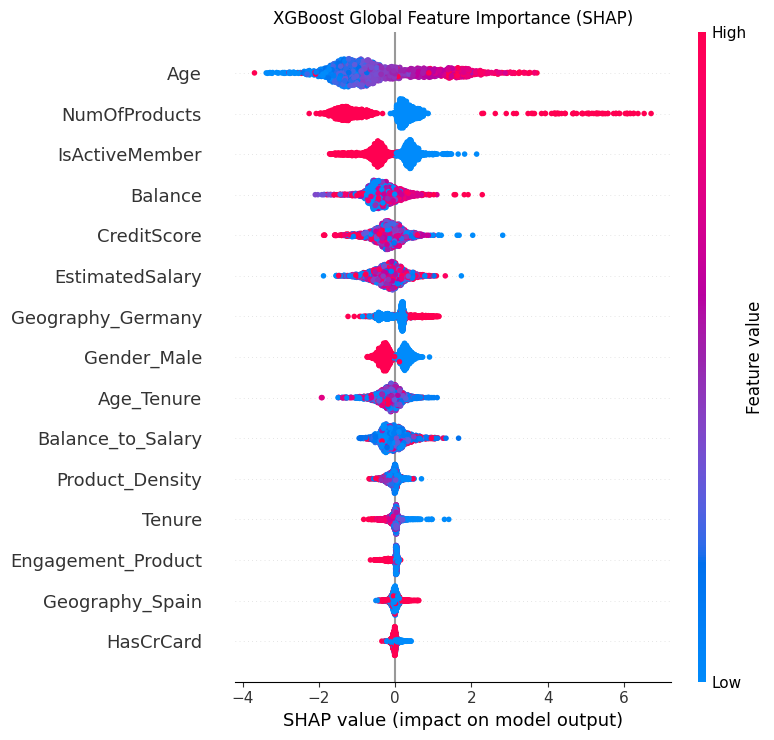

In [12]:
# ============================================================
# STEP 5: MODEL EXPLAINABILITY (SHAP ANALYSIS)
# ============================================================
import shap
import matplotlib.pyplot as plt

print("Generating SHAP values for the XGBoost model...")

# 1. Initialize the SHAP explainer with our best model (XGBoost)
xgb_model = models["XGBoost"]
explainer = shap.TreeExplainer(xgb_model)

# 2. Calculate SHAP values for the testing dataset
shap_values = explainer.shap_values(X_test_scaled_df)

# 3. Generate the SHAP Summary Plot
plt.figure(figsize=(10, 6))
plt.title("XGBoost Global Feature Importance (SHAP)")
shap.summary_plot(shap_values, X_test_scaled_df, show=False)
plt.tight_layout()
plt.show()

In [13]:
import joblib

# Save the trained XGBoost model and the StandardScaler
joblib.dump(models["XGBoost"], 'xgboost_churn_model.pkl')
joblib.dump(scaler, 'churn_scaler.pkl')

print("Model and Scaler successfully saved for the Streamlit app!")

Model and Scaler successfully saved for the Streamlit app!
